# Дашборд проекта Тіл Mix
Срез 19.11.2026. Для запуска нужен matplotlib. Факты потока и DORA читаются из сохранённых событий. Бюджет и зависимости относятся к срезу ЛЗ 14.


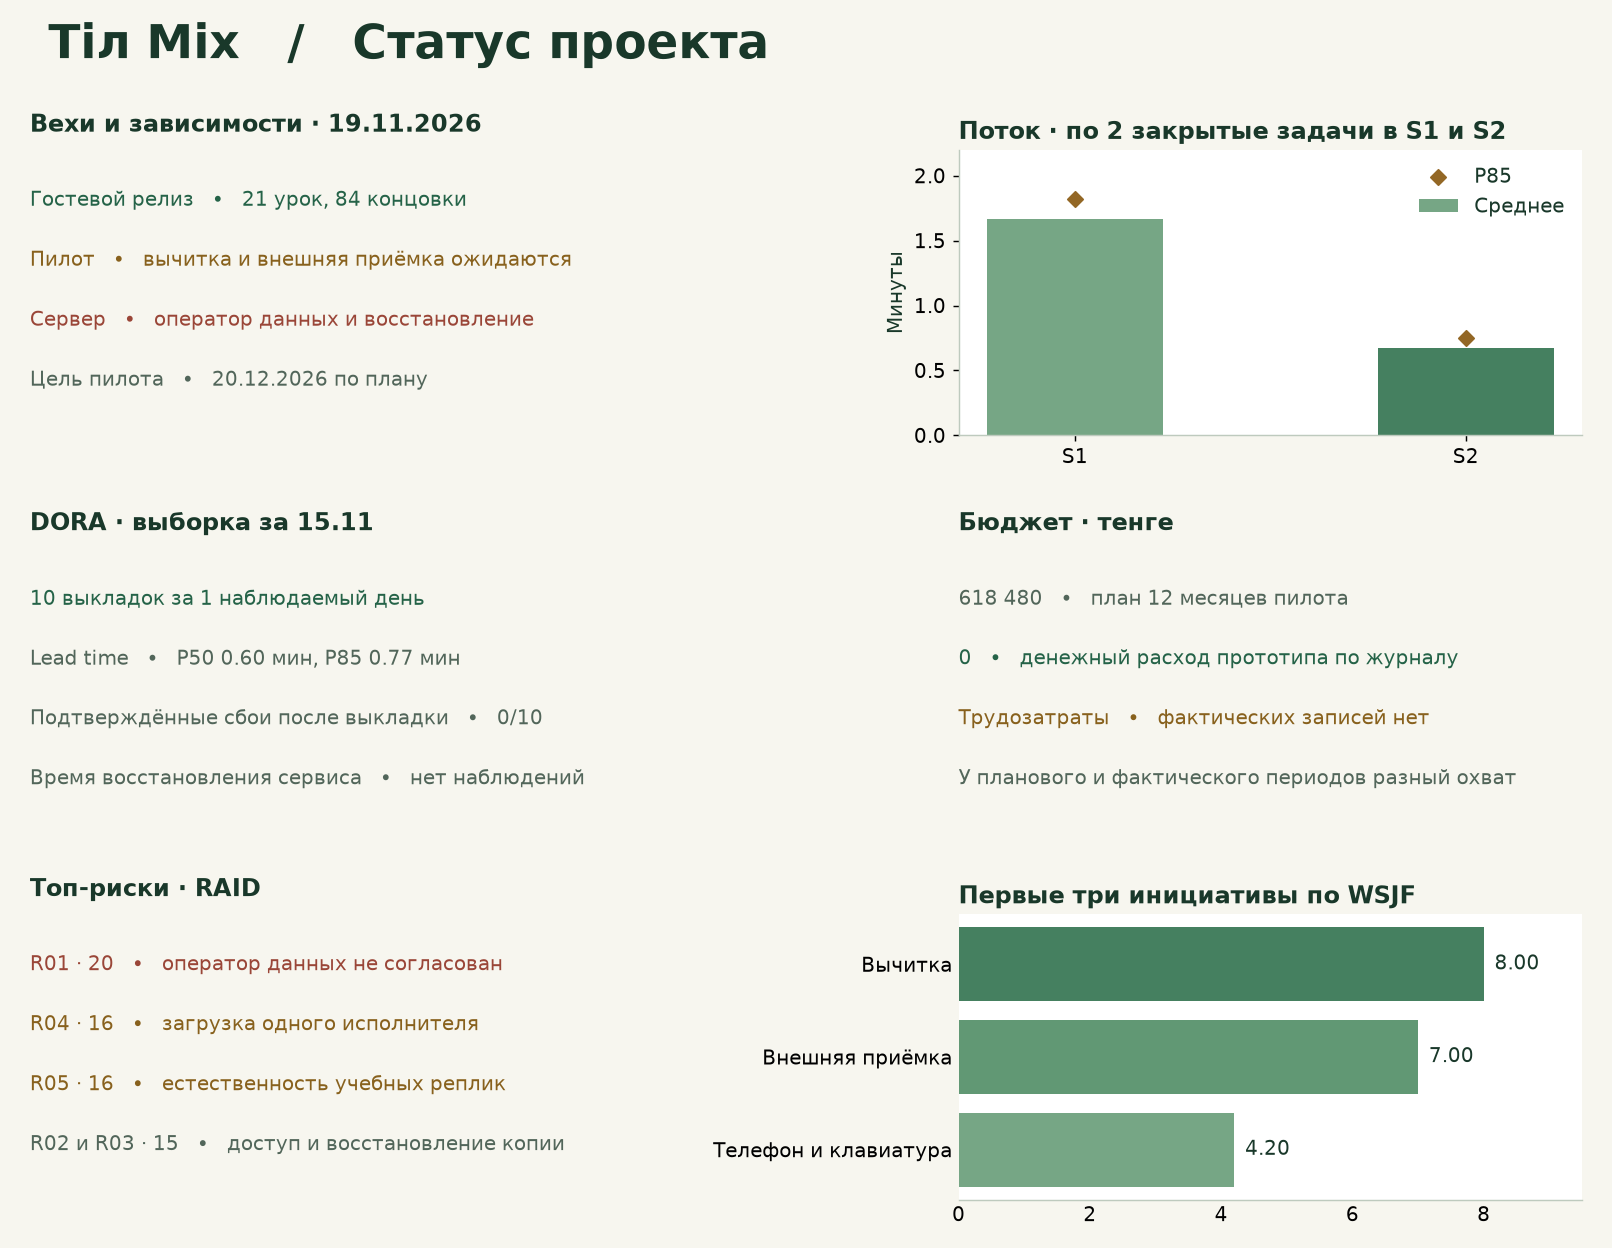

In [1]:
import csv
import json
import runpy
from pathlib import Path
import matplotlib.pyplot as plt

course = Path('course') if Path('course/flow-evidence.json').exists() else Path.cwd()
helpers = runpy.run_path(str(course / 'delivery-metrics.py'))
flow = helpers['flow_stats'](json.loads((course / 'flow-evidence.json').read_text(encoding='utf-8')))
dora = helpers['dora_stats'](json.loads((course / 'dora-evidence.json').read_text(encoding='utf-8')))
with (course / 'lab-14-wsjf.csv').open(encoding='utf-8', newline='') as source:
    portfolio = list(csv.DictReader(source))
for row in portfolio:
    row['score'] = sum(int(row[key]) for key in ('value', 'urgency', 'risk')) / int(row['size'])
portfolio.sort(key=lambda row: (-row['score'], -int(row['risk']), row['id']))
assert len(portfolio) == 10 and [row['id'] for row in portfolio[:3]] == ['P01', 'P02', 'P03']

plt.rcParams.update({'font.family': 'DejaVu Sans', 'text.color': '#19382A', 'axes.titleweight': 'bold',
                     'axes.labelcolor': '#19382A', 'axes.edgecolor': '#BECABE', 'font.size': 11})
fig, axes = plt.subplots(3, 2, figsize=(12.4, 9.6), layout='constrained', facecolor='#F7F6EF')
fig.suptitle('Тіл Mix   /   Статус проекта', fontsize=26, fontweight='bold', x=.03, ha='left')
fig.get_layout_engine().set(h_pad=.17, w_pad=.23)

def text_block(axis, title, lines):
    axis.set_axis_off()
    axis.set_title(title, loc='left', pad=10)
    for index, (line, color) in enumerate(lines):
        axis.text(0, .87 - index * .21, line, transform=axis.transAxes, color=color, fontsize=11,
                  linespacing=1.35, va='top')

green, amber, red, mute = '#256348', '#88611D', '#9A4638', '#52665A'
text_block(axes[0, 0], 'Вехи и зависимости · 19.11.2026', [
    ('Гостевой релиз   •   21 урок, 84 концовки', green),
    ('Пилот   •   вычитка и внешняя приёмка ожидаются', amber),
    ('Сервер   •   оператор данных и восстановление', red),
    ('Цель пилота   •   20.12.2026 по плану', mute),
])

ax = axes[0, 1]
ax.set_title('Поток · по 2 закрытые задачи в S1 и S2', loc='left')
ax.bar([row['cycle'] for row in flow], [row['mean_minutes'] for row in flow], color=['#76A685', '#458060'], width=.45, label='Среднее')
ax.scatter([row['cycle'] for row in flow], [row['p85_minutes'] for row in flow], color='#936725', marker='D', label='P85', zorder=3)
ax.set(ylabel='Минуты', ylim=(0, 2.2))
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')

text_block(axes[1, 0], 'DORA · выборка за 15.11', [
    (f"{dora['deployments']} выкладок за {dora['observed_days']} наблюдаемый день", green),
    (f"Lead time   •   P50 {dora['lead_p50_minutes']:.2f} мин, P85 {dora['lead_p85_minutes']:.2f} мин", mute),
    (f"Подтверждённые сбои после выкладки   •   0/{dora['deployments']}", mute),
    ('Время восстановления сервиса   •   нет наблюдений', mute),
])
text_block(axes[1, 1], 'Бюджет · тенге', [
    ('618 480   •   план 12 месяцев пилота', mute),
    ('0   •   денежный расход прототипа по журналу', green),
    ('Трудозатраты   •   фактических записей нет', amber),
    ('У планового и фактического периодов разный охват', mute),
])
text_block(axes[2, 0], 'Топ-риски · RAID', [
    ('R01 · 20   •   оператор данных не согласован', red),
    ('R04 · 16   •   загрузка одного исполнителя', amber),
    ('R05 · 16   •   естественность учебных реплик', amber),
    ('R02 и R03 · 15   •   доступ и восстановление копии', mute),
])
ax = axes[2, 1]
ax.set_title('Первые три инициативы по WSJF', loc='left')
top = portfolio[:3][::-1]
bars = ax.barh(['Телефон и клавиатура', 'Внешняя приёмка', 'Вычитка'], [row['score'] for row in top],
               color=['#76A685', '#619874', '#458060'])
ax.bar_label(bars, fmt='%.2f', padding=6)
ax.set(xlim=(0, 9.5))
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(length=0)
fig.savefig(course / 'lab-14-dashboard.png', dpi=130)
plt.show()
